In [1]:
# 202431052_Anfal Ridho Hanif
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 202431052_Anfal Ridho Hanif
df = pd.read_csv("komikcast_data.csv")
display(df.head())
df.info()
display(df.describe())
print(df.isna().sum())
print(df["tipe"].unique())
print(df["tipe"].value_counts())

,judul,tipe,status,chapter_terbaru,rating
0,Reincarnated as the Archduke’s Son,Manhwa,Ongoing,56.0,9.7
1,The Supreme Demon Swordmaster,Manhua,Ongoing,60.0,10.0
2,Black Killer Whale Baby,Manhwa,Ongoing,128.0,10.0
3,Student Jo-Eun,Manhwa,Ongoing,95.0,10.0
4,The Saint Levels Up Through Necromancy,Manhwa,Ongoing,45.0,9.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   judul            266 non-null    object 
 1   tipe             266 non-null    object 
 2   status           266 non-null    object 
 3   chapter_terbaru  266 non-null    float64
 4   rating           266 non-null    float64
dtypes: float64(2), object(3)
memory usage: 10.5+ KB


,chapter_terbaru,rating
count,266.000000,266.000000
mean,172.768421,9.617669
std,519.536015,0.859941
min,2.300000,2.000000
25%,33.000000,9.600000
50%,70.000000,10.000000
75%,179.750000,10.000000
max,7199.000000,10.000000


judul              0
tipe               0
status             0
chapter_terbaru    0
rating             0
dtype: int64
['Manhwa' 'Manhua' 'Manga']
Manhwa    138
Manga      78
Manhua     50
Name: tipe, dtype: int64


In [3]:
# 202431052_Anfal Ridho Hanif
x = df.drop(columns=["judul", "tipe", "status"])
y = df["tipe"]

print("Kolom fitur:", list(x.columns))
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_angka = le.fit_transform(y)          # teks -> angka

x = np.array(x, dtype=np.float64)
y = np.array(y_angka, dtype=np.int64)

# Pemetaan kelas (urutan alfabet)
for kode, nama in enumerate(le.classes_):
    print(kode, "=", nama)
print(x.dtype, y.dtype, x.shape, y.shape)

Kolom fitur: ['chapter_terbaru', 'rating']
0 = Manga
1 = Manhua
2 = Manhwa
float64 int64 (266, 2) (266,)


In [4]:
# 202431052_Anfal Ridho Hanif
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=0
)
print("Data latih:", x_train.shape[0])
print("Data uji  :", x_test.shape[0])

model = DecisionTreeClassifier(random_state=0)
model.fit(x_train, y_train)

Data latih: 186
Data uji  : 80


DecisionTreeClassifier(random_state=0)

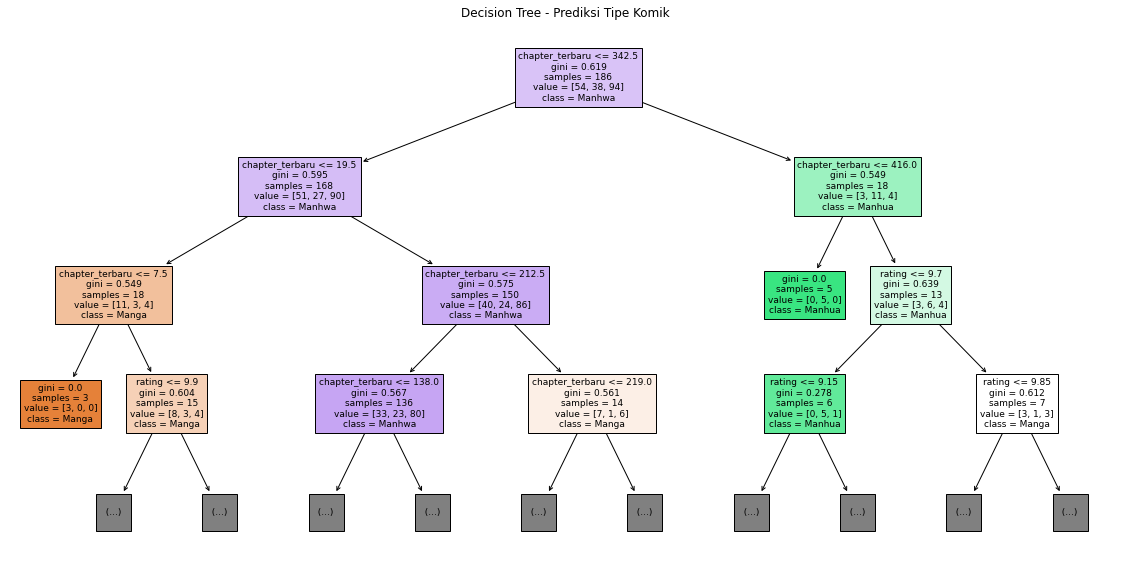

Kedalaman pohon penuh: 16
Jumlah daun          : 93
202431052_Anfal Ridho Hanif


In [10]:
# 202431052_Anfal Ridho Hanif
from sklearn import tree

plt.figure(figsize=(20, 10))
tree.plot_tree(
    model,
    feature_names=["chapter_terbaru", "rating"],
    class_names=le.classes_,
    filled=True,
    max_depth=3,        # tampilkan 3 level teratas agar terbaca
    fontsize=9,
)
plt.title("Decision Tree - Prediksi Tipe Komik")
plt.show()

print("Kedalaman pohon penuh:", model.get_depth())
print("Jumlah daun          :", model.get_n_leaves())
print("202431052_Anfal Ridho Hanif")

In [9]:
# 202431052_Anfal Ridho Hanif
x_baru = np.array([[500, 9.5]], dtype=np.float64)

pred = model.predict(x_baru)
print("Kode prediksi :", pred[0])
print("Tipe prediksi :", le.inverse_transform(pred)[0])
from sklearn.metrics import accuracy_score

y_pred = model.predict(x_test)
akurasi = accuracy_score(y_test, y_pred)
print("Akurasi:", akurasi)

Kode prediksi : 1
Tipe prediksi : Manhua
Akurasi: 0.4375


In [8]:
# 202431052_Anfal Ridho Hanif
from sklearn.metrics import classification_report

print(classification_report(
    y_test, y_pred,
    labels=range(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0,
))

              precision    recall  f1-score   support

       Manga       0.36      0.42      0.38        24
      Manhua       0.13      0.17      0.15        12
      Manhwa       0.62      0.52      0.57        44

    accuracy                           0.44        80
   macro avg       0.37      0.37      0.37        80
weighted avg       0.47      0.44      0.45        80

